In [5]:
def square(x):
    return x**2

square(4)
INK = 'green'
BLUE = 'blue'
ORANGE = 'orange'
STAR = dict(marker = '*', s = 200, color = 'orange', edgecolor = 'white', linewidth = 0.6)
ARROW = dict(arrowstyle = "-|>", mutation_scale = 13, lw = 2.0, shrinkA=0, shrinkB=0)
NOTE = dict(fontsize = 8, color = 'black', ha = 'left', va='center',
            bbox = dict(boxstyle='round,pad=0.25', fc ='white', ec = 'none', alpha = 0.9))

In [6]:
import numpy as np
import matplotlib.pyplot as plt

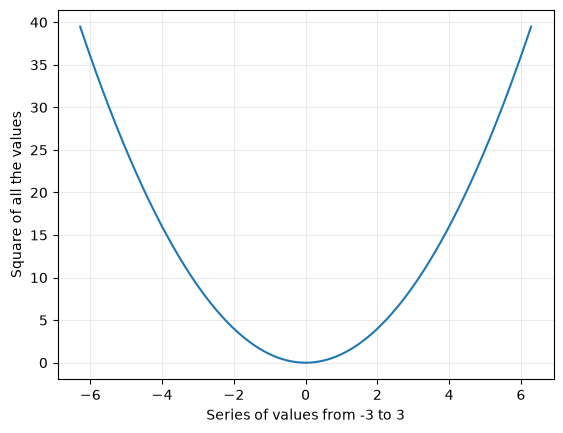

In [7]:
x = np.linspace(-2*np.pi, 2*np.pi, 600)

plt.plot(x, square(x))
plt.xlabel("Series of values from -3 to 3")
plt.ylabel("Square of all the values")
plt.grid(alpha = 0.25)
plt.show()



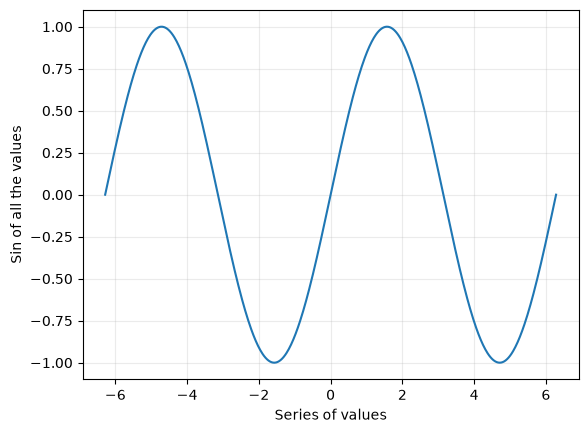

In [8]:
y = np.sin(x)
plt.plot(x, y)
plt.xlabel("Series of values")
plt.ylabel("Sin of all the values")
plt.grid(alpha = 0.25)
plt.show()


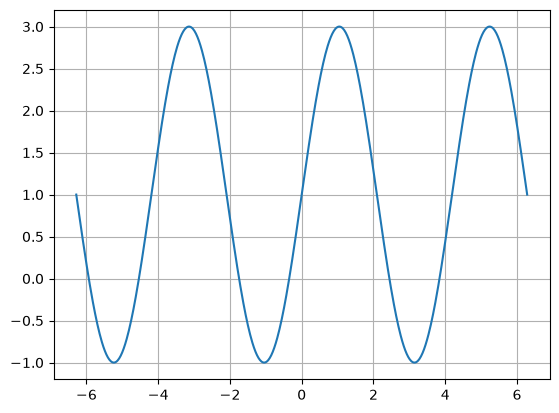

In [9]:
a, b, c = 2.0, 1.5, 1.0

y = a*np.sin(b*x) + c

plt.plot(x, y)
plt.grid()
plt.show()


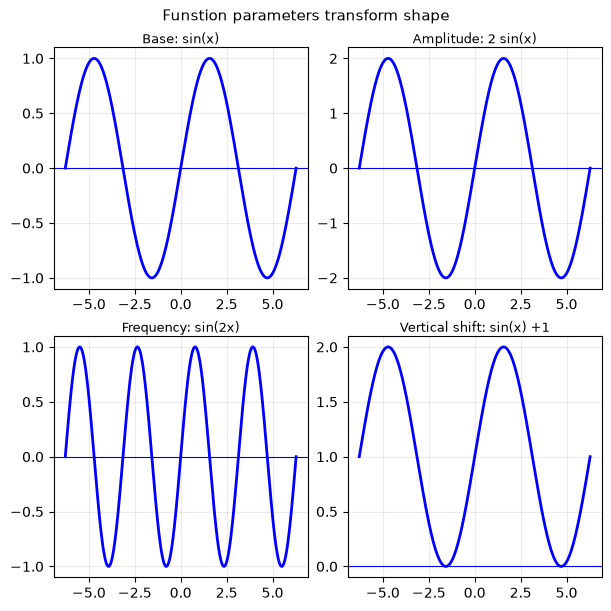

In [10]:
panels = [
    ("Base: sin(x)",                 1.0, 1.0, 0.0),
    ("Amplitude: 2 sin(x)",          2.0, 1.0, 0.0),
    ("Frequency: sin(2x)",           1.0, 2.0, 0.0),
    ("Vertical shift: sin(x) +1",    1.0, 1.0, 1.0)
]

fig, axes = plt.subplots(2,2, figsize = (6,6), layout = 'constrained')
for ax, (title, a, b, c) in zip(axes.ravel(), panels):
    ax.axhline(0, color = 'blue', lw = 0.8)
    ax.plot(x, a * np.sin(b*x) + c, color = 'blue', lw = 2.0)
    ax.set_title(title, fontsize = 9, pad = 3)
    ax.grid(alpha = 0.25)
fig.suptitle("Funstion parameters transform shape", fontsize = 10.5)
plt.show()



## Slope of a function

In [11]:
def f(x):
    return x**2

x0 = 2.0
for h in [1.5, 0.6, 0.2, 0.05, 0.01, 0.001]:
    slope = (f(x0 + h) - f(x0)) / h
    print(f"h = {h}    slope = {slope:.4f}")

h = 1.5    slope = 5.5000
h = 0.6    slope = 4.6000
h = 0.2    slope = 4.2000
h = 0.05    slope = 4.0500
h = 0.01    slope = 4.0100
h = 0.001    slope = 4.0010


In [12]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [13]:
x0 = 2.0
gaps = np.geomspace(1.5, 0.01, 30)
x = np.linspace(0, 4.5, 200)

fig, ax = plt.subplots(figsize = (6, 4), layout = 'constrained')
ax.plot(x, f(x), color = 'blue', lw = 2.)
secant, = ax.plot([], [], color = 'orange', lw = 1.6, ls = '--')
two_points = ax.scatter([x0, x0], [f(x0), f(x0)], color = 'green', s = 28, zorder = 3)
ax.set_xlabel("X")
ax.set_ylabel("f(x)")
ax.set_ylim(f(x).min() - 3, f(x).max() + 2)
ax.grid(alpha = 0.25)

def draw(frame):
    h = gaps[frame]
    slope = (f(x0 + h) - f(x0)) / h
    secant.set_data(x, f(x0) + slope * (x - x0))
    two_points.set_offsets([[x0, f(x0)], [x0 + h, f(x0 + h)]])
    ax.set_title(f"h = {h:.3f}    slope = {slope:.3f}")

animation = FuncAnimation(fig, draw, frames = len(gaps), interval = 250)
plt.close(fig)
HTML(animation.to_jshtml())

In [14]:
def numerical_derivative(f, x, h = 1e-5):
    return (f(x + h) - f(x)) / h

print(numerical_derivative(lambda z: z**2, 3))

6.000009999951316


In [15]:
def f(x):
    return x **3 

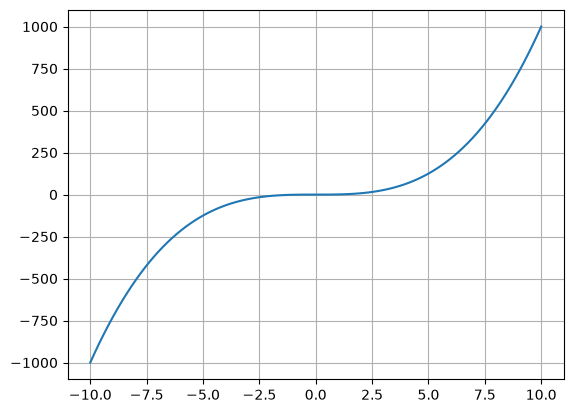

In [16]:
x = np.linspace(-10, 10, 100)
plt.plot(x, f(x))
plt.grid()

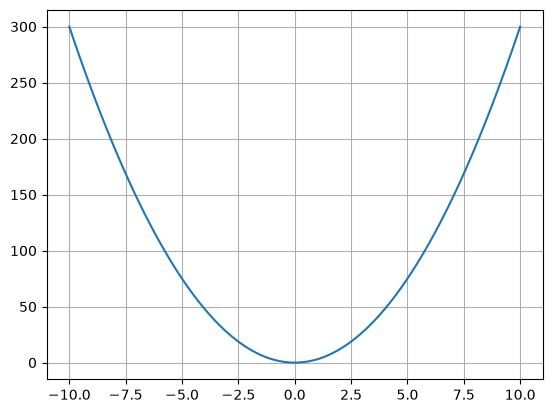

In [17]:
def first_derivative(x):
    return 3 * x**2

plt.plot(x, first_derivative(x))
plt.grid()
plt.show()

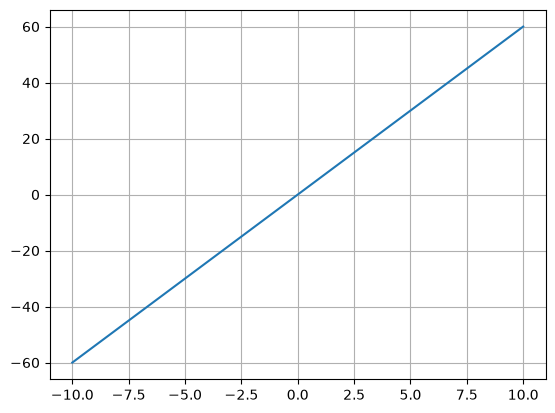

In [18]:
def second_derivative(x):
    return 6 * x

plt.plot(x, second_derivative(x))
plt.grid()
plt.show()

## Loss

In [19]:
actual = 10

for prediction in [2,6,9, 10, 13]:
    loss = (actual - prediction)**2
    print(prediction, loss)

2 64
6 16
9 1
10 0
13 9


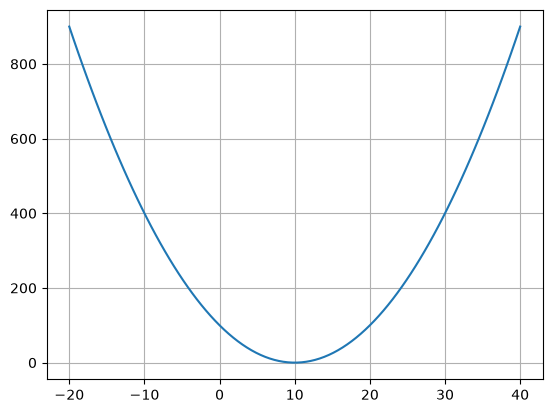

In [20]:
target = 10

prediction = np.linspace(-20, 40, 100)

def loss(target, prediction):
    return (target - prediction)**2

plt.plot(prediction, loss(target, prediction=prediction))
plt.grid()
plt.show()

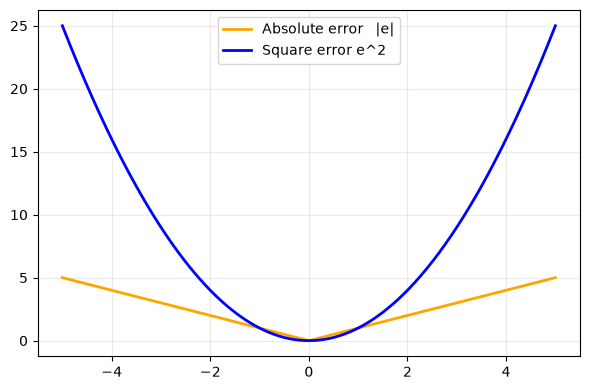

In [21]:
e = np.linspace(-5, 5, 400)

fig, ax = plt.subplots(figsize = (6.0, 4))
ax.plot(e, np.abs(e), color = 'orange', lw = 2.0, label = 'Absolute error   |e|')
ax.plot(e, e**2, color = 'blue', lw = 2.0, label = 'Square error e^2')
ax.legend(loc = 'upper center')
ax.grid(alpha  =0.25)
fig.tight_layout()
plt.show()

In [22]:
import numpy as np

In [23]:
# how hard does each loss push back?
# The slope of e^2 is 2e: it grows with the error. The slope of |e| is +1 or -1 (away from e=0).
# if the prediction is too low, should gradient descent increase or decrease it?
for e in [-20, -4, -1, -0.1, 0.1, 1, 4, 20]:
    print(f"error={e:>6}    slope of e^2 = {2*e:>6}    slope of |e| = {np.sign(e):>4}")

# SAME loss, DIFFERENT variable: e = actual - prediction, so de/dprediction = -1.
actual = 10
for prediction in [6, 13]:
    error = actual - prediction
    dL_de = 2 * error
    dL_dprediction = dL_de * (-1)            # chain rule: dL/dprediction = -2e
    move = "up" if dL_dprediction < 0 else "down"
    print(f"prediction={prediction:>2}  e={error:>2}  dL/de={dL_de:>3}  "
          f"dL/dprediction={dL_dprediction:>3}  => descent moves prediction {move}")


error=   -20    slope of e^2 =    -40    slope of |e| =   -1
error=    -4    slope of e^2 =     -8    slope of |e| =   -1
error=    -1    slope of e^2 =     -2    slope of |e| =   -1
error=  -0.1    slope of e^2 =   -0.2    slope of |e| = -1.0
error=   0.1    slope of e^2 =    0.2    slope of |e| =  1.0
error=     1    slope of e^2 =      2    slope of |e| =    1
error=     4    slope of e^2 =      8    slope of |e| =    1
error=    20    slope of e^2 =     40    slope of |e| =    1
prediction= 6  e= 4  dL/de=  8  dL/dprediction= -8  => descent moves prediction up
prediction=13  e=-3  dL/de= -6  dL/dprediction=  6  => descent moves prediction down


In [24]:
X = np.array([1., 2., 3., 4., 5.])
y = 2*X + 1

def loss(w, b):
    return np.mean((y - (w*X + b))**2)

w, b, h = 4.0, 7.0, 1e-5
dL_dw = (loss(w+h, b) - loss(w, b)) / h
dL_db = (loss(w, b+h) - loss(w, b)) / h

print(dL_dw, dL_db)

80.00010999751339 24.00000999784879


In [25]:
# SHARED - the same five points and loss, under names the later labs will not overwrite
X_data = np.array([1., 2., 3., 4., 5.])
y_data = 2*X_data + 1                                  # the rule hiding in the data: w=2, b=1
w_best, b_best = np.polyfit(X_data, y_data, 1)         # the true minimum, computed directly

def mse(w, b):
    return np.mean((y_data - (w*X_data + b))**2)

def measure_gradient(w, b, h=1e-5):
    """Lab 5B as a function: nudge w, nudge b, see how the loss reacts."""
    return np.array([(mse(w + h, b) - mse(w, b)) / h,
                     (mse(w, b + h) - mse(w, b)) / h])

def draw_landscape(ax, w_range, b_range):
    """Contour map of the loss over every (w, b) in the given ranges."""
    W, B = np.meshgrid(np.linspace(*w_range, 250), np.linspace(*b_range, 250))
    L = np.vectorize(mse)(W, B)
    contours = ax.contour(W, B, L, levels=[0.05, 0.2, 0.5, 1, 2, 5, 10, 20, 40, 80],
                          cmap="viridis", linewidths=1.0)
    ax.set_xlim(*w_range)
    ax.set_ylim(*b_range)
    ax.set_xlabel("w")
    ax.set_ylabel("b")
    ax.grid(alpha=0.25)
    return contours

print("true minimum: w =", round(w_best, 6), " b =", round(b_best, 6))
print("gradient measured at w=0, b=0:", measure_gradient(0.0, 0.0))

true minimum: w = 2.0  b = 1.0
gradient measured at w=0, b=0: [-49.99989 -13.99999]


In [26]:
import matplotlib.pyplot as plt

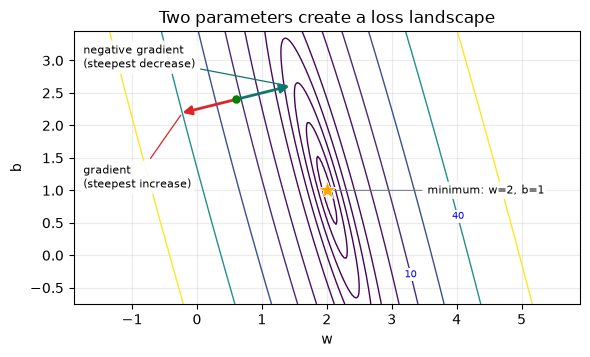

gradient at (0.6, 2.4) = [-22.4  -5.6]
angle between the downhill arrow and the line to the minimum: 59 degrees


In [27]:
# Two parameters create a loss landscape
# move the point (w0, b0). Does the red arrow stay perpendicular to the contour?
w0, b0 = 0.6, 2.4
g = measure_gradient(w0, b0)
u = g / np.linalg.norm(g)                               # direction only: length 1
uphill = (w0 + 0.85*u[0], b0 + 0.85*u[1])
downhill = (w0 - 0.85*u[0], b0 - 0.85*u[1])

fig, ax = plt.subplots(figsize=(6.0, 3.75))
draw_landscape(ax, (-1.9, 5.9), (-0.75, 3.45))
for level, spot in [(10, (3.29, -0.3)), (40, (4.02, 0.6))]:        # name two contour lines
    ax.text(*spot, str(level), fontsize=7, color='blue', ha="center", va="center",
            bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none"))
ax.set_aspect("equal")                                  # so perpendicular looks perpendicular

ax.annotate("", xy=uphill, xytext=(w0, b0), arrowprops=dict(color="#dc2626", **ARROW))
ax.annotate("", xy=downhill, xytext=(w0, b0), arrowprops=dict(color="#0f766e", **ARROW))
ax.scatter([w0], [b0], color='green', s=26, zorder=5)
ax.scatter([w_best], [b_best], zorder=6, **STAR)

ax.annotate("gradient\n(steepest increase)", xy=uphill, xytext=(-1.75, 1.2),
            arrowprops=dict(arrowstyle="-", color="#dc2626", lw=0.9), **NOTE)
ax.annotate("negative gradient\n(steepest decrease)", xy=downhill, xytext=(-1.75, 3.05),
            arrowprops=dict(arrowstyle="-", color="#0f766e", lw=0.9), **NOTE)
ax.annotate(f"minimum: w={w_best:.0f}, b={b_best:.0f}", xy=(w_best, b_best), xytext=(3.55, 1.0),
            arrowprops=dict(arrowstyle="-", color="#6b7280", lw=0.7), **NOTE)
ax.set_title("Two parameters create a loss landscape")
fig.tight_layout()
plt.show()

to_minimum = np.array([w_best - w0, b_best - b0])
angle = np.degrees(np.arccos(np.dot(-u, to_minimum) / np.linalg.norm(to_minimum)))
print(f"gradient at ({w0}, {b0}) = {np.round(g, 2)}")
print(f"angle between the downhill arrow and the line to the minimum: {angle:.0f} degrees")


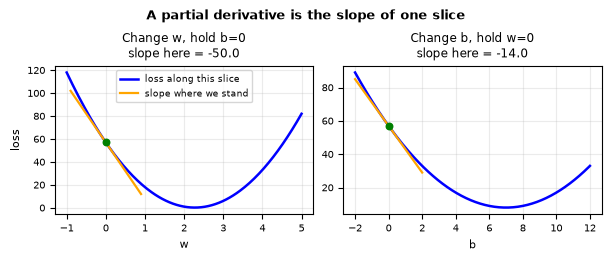

slope along w = -50.0    slope along b = -14.0


In [28]:
# One knob at a time: a partial derivative is the slope of a slice
# change where we stand (w0, b0). Which slice gets steeper?
w0, b0 = 0.0, 0.0
slope_w, slope_b = measure_gradient(w0, b0)             # the two numbers measures

w_values = np.linspace(-1, 5, 200)
b_values = np.linspace(-2, 12, 200)
loss_along_w = [mse(w, b0) for w in w_values]           # change w, hold b fixed
loss_along_b = [mse(w0, b) for b in b_values]           # change b, hold w fixed
here = mse(w0, b0)
reach_w, reach_b = np.array([-0.9, 0.9]), np.array([-2.0, 2.0])   # length of each slope line

fig, (left, right) = plt.subplots(1, 2, figsize=(6.0, 2.5), layout="constrained")
left.plot(w_values, loss_along_w, color=BLUE, lw=1.8, label="loss along this slice")
left.plot(w0 + reach_w, here + slope_w * reach_w, color=ORANGE, lw=1.6,
          label="slope where we stand")
left.scatter([w0], [here], color='green', s=22, zorder=3)
left.set_title(f"Change w, hold b={b0:g}\nslope here = {slope_w:.1f}", fontsize=8.5)
left.set_xlabel("w", fontsize=8)
left.set_ylabel("loss", fontsize=8)
left.legend(fontsize=6.5, loc="upper center")

right.plot(b_values, loss_along_b, color='blue', lw=1.8)
right.plot(b0 + reach_b, here + slope_b * reach_b, color='orange', lw=1.6)
right.scatter([b0], [here], color=INK, s=22, zorder=3)
right.set_title(f"Change b, hold w={w0:g}\nslope here = {slope_b:.1f}", fontsize=8.5)
right.set_xlabel("b", fontsize=8)

for ax in (left, right):
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.25)
fig.suptitle("A partial derivative is the slope of one slice", fontsize=9.5, fontweight="bold")
plt.show()

print(f"slope along w = {slope_w:.1f}    slope along b = {slope_b:.1f}")


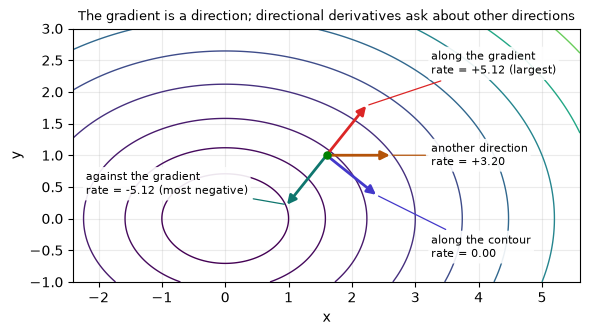

gradient: [3.2 4. ]   length: 5.12


In [29]:
# One gradient, many directions

# change `other` to any direction you like, for example (0, 1) or (-1, 1)
point = np.array([1.6, 1.0])
other = np.array([1.0, 0.0])

grad = np.array([2 * point[0], 4 * point[1]])           # f(x, y) = x^2 + 2y^2
along = grad / np.linalg.norm(grad)                     # unit direction of the gradient
contour_dir = np.array([along[1], -along[0]])           # a quarter turn away: along the contour
other = other / np.linalg.norm(other)

def rate(u):
    """Rate of change of f when we step in unit direction u."""
    return 0.0 + round(float(np.dot(grad, u)), 2)

fig, ax = plt.subplots(figsize=(6.0, 3.3))
xs, ys = np.meshgrid(np.linspace(-2.4, 5.6, 300), np.linspace(-1.0, 3.0, 300))
ax.contour(xs, ys, xs**2 + 2 * ys**2, levels=[1, 2.5, 5, 9, 14, 20, 27, 35, 45, 58],
           cmap="viridis", linewidths=1.0)
ax.set_aspect("equal")
ax.set_xlim(-2.4, 5.6)
ax.set_ylim(-1.0, 3.0)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(alpha=0.25)

directions = [along, -along, contour_dir, other]
colors = ["#dc2626", "#0f766e", "#4338ca", "#b45309"]
labels = [f"along the gradient\nrate = {rate(along):+.2f} (largest)",
          f"against the gradient\nrate = {rate(-along):+.2f} (most negative)",
          f"along the contour\nrate = {abs(rate(contour_dir)):.2f}",
          f"another direction\nrate = {rate(other):+.2f}"]
label_spots = [(3.25, 2.45), (-2.2, 0.55), (3.25, -0.45), (3.25, 1.0)]

for u, c, text, spot in zip(directions, colors, labels, label_spots):
    tip = point + u
    ax.annotate("", xy=tip, xytext=point, arrowprops=dict(color=c, **ARROW))
    ax.annotate(text, xy=tip, xytext=spot,
                arrowprops=dict(arrowstyle="-", color=c, lw=0.9), **NOTE)
ax.scatter(*point, color=INK, s=26, zorder=5)
ax.set_title("The gradient is a direction; directional derivatives ask about other directions",
             fontsize=9.5)
fig.tight_layout()
plt.show()

print("gradient:", grad, "  length:", round(float(np.linalg.norm(grad)), 2))


In [30]:
#  Gradient descent on one scalar
prediction = 2.0
learning_rate = 0.2

for step in range(30):
    gradient = -2 * (10 - prediction)
    prediction = prediction - learning_rate * gradient
    loss = (10 - prediction)**2
    print(step, prediction, loss)

0 5.2 23.04
1 7.12 8.2944
2 8.272 2.9859839999999993
3 8.9632 1.074954239999999
4 9.37792 0.3869835264000005
5 9.626752 0.1393140695040002
6 9.7760512 0.05015306502144023
7 9.86563072 0.01805510340771829
8 9.919378432 0.006499837226778584
9 9.9516270592 0.0023399414016403246
10 9.97097623552 0.0008423789045904963
11 9.982585741312 0.0003032564056525663
12 9.9895514447872 0.00010917230603493871
13 9.993730866872319 3.9302030172586845e-05
14 9.996238520123391 1.4148730862131265e-05
15 9.997743112074035 5.093543110365652e-06
16 9.998645867244422 1.8336755197297101e-06
17 9.999187520346654 6.601231871015411e-07
18 9.999512512207993 2.376443473562084e-07
19 9.999707507324796 8.555196504781937e-08
20 9.999824504394878 3.079870741709028e-08
21 9.999894702636928 1.1087534670002863e-08
22 9.999936821582157 3.9915124811561395e-09
23 9.999962092949295 1.4369444931892757e-09
24 9.999977255769577 5.173000175158177e-10
25 9.999986353461747 1.8622800629599793e-10
26 9.999991812077049 6.70420822549235

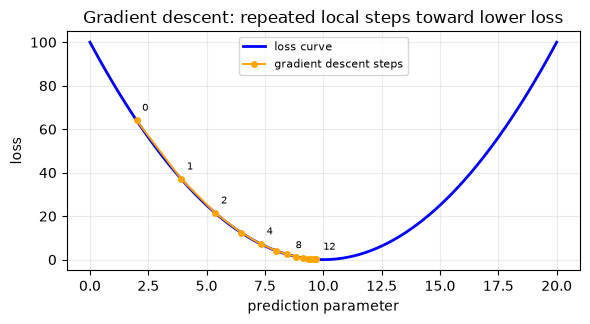

In [31]:
# Gradient descent: repeated local steps toward lower loss
# start at 18 instead of 2. Which way does it move, and why?
start, learning_rate, steps = 2.0, 0.12, 12

path = [start]
for step in range(steps):
    gradient = -2 * (10 - path[-1])
    path.append(path[-1] - learning_rate * gradient)
path = np.array(path)

p = np.linspace(0, 20, 400)
fig, ax = plt.subplots(figsize=(6.0, 3.34))
ax.plot(p, (10 - p)**2, color=BLUE, lw=2.0, label="loss curve")
ax.plot(path, (10 - path)**2, color=ORANGE, lw=1.4, marker="o", ms=4,
        label="gradient descent steps")
# which steps get a number, and how far the number sits from its dot
numbered = {0: (4, 7), 1: (4, 7), 2: (4, 7), 4: (4, 7), 8: (-5, 7), 12: (5, 7)}
for n, shift in numbered.items():
    if n < len(path):
        ax.annotate(str(n), (path[n], (10 - path[n])**2), xytext=shift,
                    textcoords="offset points", fontsize=7)
ax.set_title("Gradient descent: repeated local steps toward lower loss")
ax.set_xlabel("prediction parameter")
ax.set_ylabel("loss")
ax.legend(loc="upper center", fontsize=8)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

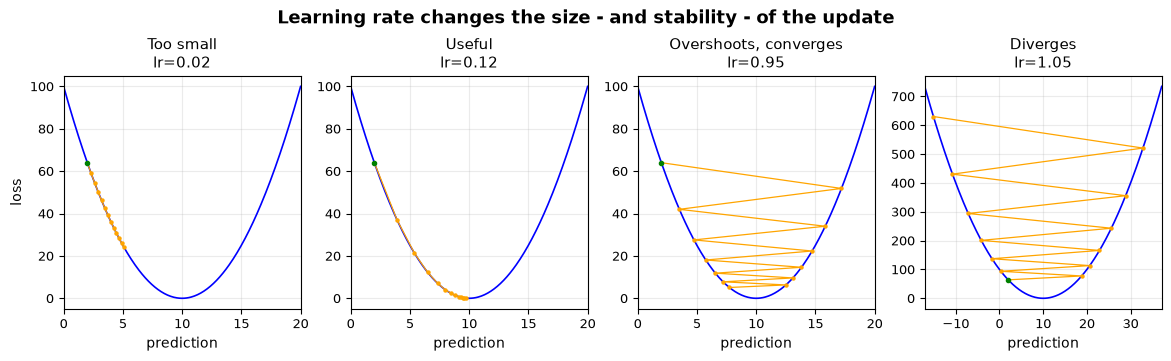

lr=0.02  prediction after 12 updates = 5.0983
lr=0.12  prediction after 12 updates = 9.7029
lr=0.95  prediction after 12 updates = 7.7406
lr=1.05  prediction after 12 updates = -15.1074


In [32]:
# Learning rate changes the size - and stability - of the update
# change a learning rate to 0.5, then to 1.0. Predict each before you run it.
cases = [(0.02, "Too small"), (0.12, "Useful"),
         (0.95, "Overshoots, converges"), (1.05, "Diverges")]
final_prediction = {}

fig, axes = plt.subplots(1, 4, figsize=(11.6, 3.5), layout="constrained")
for ax, (lr, name) in zip(axes, cases):
    prediction = 2.0
    path = [prediction]
    for step in range(12):
        gradient = -2 * (10 - prediction)
        prediction = prediction - lr * gradient
        path.append(prediction)
    path = np.array(path)
    final_prediction[lr] = path[-1]

    reach = max(10.0, np.abs(path - 10).max() + 2)      # widen the view if the path leaves 0..20
    p = np.linspace(10 - reach, 10 + reach, 300)
    ax.plot(p, (10 - p)**2, color=BLUE, lw=1.2)
    ax.plot(path, (10 - path)**2, color=ORANGE, lw=0.9, marker="o", ms=2.2)
    ax.scatter([path[0]], [(10 - path[0])**2], color=INK, s=9, zorder=4)   # the start
    ax.set_title(f"{name}\nlr={lr}", fontsize=11)
    ax.set_xlim(10 - reach, 10 + reach)
    ax.set_xlabel("prediction", fontsize=10)
    ax.tick_params(labelsize=9)
    ax.grid(alpha=0.25)
axes[0].set_ylabel("loss", fontsize=10)
fig.suptitle("Learning rate changes the size - and stability - of the update",
             fontsize=13, fontweight="bold")
plt.show()

for lr, value in final_prediction.items():
    print(f"lr={lr:<5} prediction after 12 updates = {value:.4f}")

In [33]:
# EXPERIMENT - the second derivative of (10 - p)^2 is 2,
# so each update multiplies the distance to the minimum by (1 - 2*lr)
# add your own learning rate to the list and predict its row first
for lr in [0.02, 0.12, 0.5, 0.95, 1.0, 1.05]:
    prediction = 2.0
    distances = []
    for step in range(4):
        distances.append(prediction - 10)
        prediction = prediction - lr * (-2 * (10 - prediction))
    ratios = [0.0 + round(distances[i+1] / distances[i], 3)
              for i in range(3) if distances[i] != 0]
    print(f"lr={lr:<5}  1 - 2*lr = {1 - 2*lr:+.2f}   measured: {ratios}")

lr=0.02   1 - 2*lr = +0.96   measured: [0.96, 0.96, 0.96]
lr=0.12   1 - 2*lr = +0.76   measured: [0.76, 0.76, 0.76]
lr=0.5    1 - 2*lr = +0.00   measured: [0.0]
lr=0.95   1 - 2*lr = -0.90   measured: [-0.9, -0.9, -0.9]
lr=1.0    1 - 2*lr = -1.00   measured: [-1.0, -1.0, -1.0]
lr=1.05   1 - 2*lr = -1.10   measured: [-1.1, -1.1, -1.1]


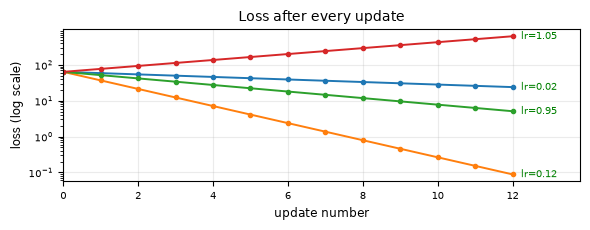

In [34]:
# Loss after every update, on a log scale
# add 1.0 to the list. What will its line look like?
learning_rates = [0.02, 0.12, 0.95, 1.05]
steps = 12

fig, ax = plt.subplots(figsize=(6.0, 2.4))
for lr in learning_rates:
    prediction = 2.0
    losses = [(10 - prediction)**2]
    for step in range(steps):
        prediction = prediction - lr * (-2 * (10 - prediction))
        losses.append((10 - prediction)**2)
    ax.plot(range(steps + 1), losses, lw=1.4, marker="o", ms=3)
    ax.annotate(f"lr={lr}", (steps, losses[-1]), xytext=(6, 0), textcoords="offset points",
                fontsize=7.5, color=INK, va="center")          # label each line at its end
ax.set_yscale("log")
ax.set_xlim(0, steps + 1.8)                                    # room for the labels
ax.set_xlabel("update number", fontsize=8.5)
ax.set_ylabel("loss (log scale)", fontsize=8.5)
ax.set_title("Loss after every update", fontsize=10)
ax.tick_params(labelsize=7.5)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

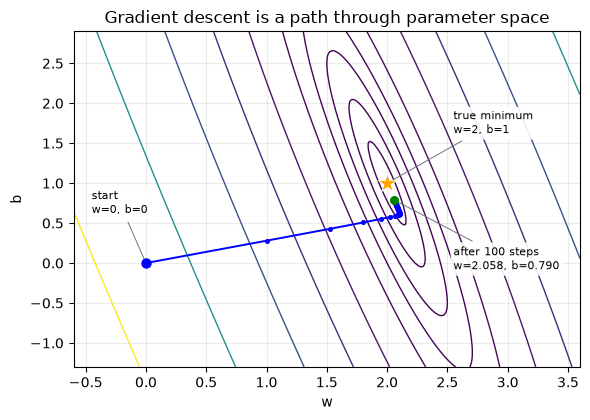

after 100 steps: w=2.0582  b=0.7898  loss=0.0080


In [35]:
# Gradient descent is a path through parameter space

# change steps from 100 to 1000. How far along the valley does it get?
steps, lr = 100, 0.02
w, b = 0.0, 0.0

path = [(w, b)]
for step in range(steps):
    dw, db = measure_gradient(w, b)                     # no formula yet: we measure the slope
    w, b = w - lr * dw, b - lr * db
    path.append((w, b))
path = np.array(path)

fig, ax = plt.subplots(figsize=(6.0, 4.3))
draw_landscape(ax, (-0.6, 3.6), (-1.3, 2.9))
ax.plot(path[:, 0], path[:, 1], color=BLUE, lw=1.4, marker="o", ms=2.6)
ax.scatter(*path[0], color=BLUE, s=42, zorder=5)
ax.scatter(*path[-1], color=INK, s=30, zorder=6)
ax.scatter([w_best], [b_best], zorder=7, **STAR)

w_end, b_end = path[-1]
note = dict(arrowprops=dict(arrowstyle="-", color="#6b7280", lw=0.7), **NOTE)
ax.annotate("start\nw=0, b=0", xy=path[0], xytext=(-0.45, 0.75), **note)
ax.annotate(f"after {steps} steps\nw={w_end:.3f}, b={b_end:.3f}",
            xy=path[-1], xytext=(2.55, 0.05), **note)
ax.annotate(f"true minimum\nw={w_best:.0f}, b={b_best:.0f}",
            xy=(w_best, b_best), xytext=(2.55, 1.75), **note)
ax.set_title("Gradient descent is a path through parameter space")
fig.tight_layout()
plt.show()

print(f"after {steps} steps: w={w_end:.4f}  b={b_end:.4f}  loss={mse(w_end, b_end):.4f}")


In [36]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [37]:
#  Watch gradient descent walk through parameter space
# change lr to 0.08 and watch it zig-zag across the valley
lr, steps = 0.02, 100
w, b = 0.0, 0.0

path = [(w, b)]
for step in range(steps):
    dw, db = measure_gradient(w, b)
    w, b = w - lr * dw, b - lr * db
    path.append((w, b))
path = np.array(path)
# early steps one by one, later ones in jumps
shown = [0, 1, 2, 3, 4, 5, 6, 8, 10, 13, 16, 20, 25, 30, 40, 50, 60, 70, 80, 90, 100]
shown = [n for n in shown if n <= steps]

fig, ax = plt.subplots(figsize=(6.0, 4.0), layout="constrained")
draw_landscape(ax, (-0.8, 4.8), (-1.3, 2.9))
ax.scatter([w_best], [b_best], zorder=7, **STAR)
trail, = ax.plot([], [], color=BLUE, lw=1.4, marker="o", ms=2.6)
head = ax.scatter([path[0, 0]], [path[0, 1]], color=INK, s=34, zorder=6)

def draw(frame):
    n = shown[frame]
    w_now, b_now = path[n]
    trail.set_data(path[:n + 1, 0], path[:n + 1, 1])
    head.set_offsets([[w_now, b_now]])
    loss_now = mse(w_now, b_now)
    ax.set_title(f"step {n}:   w = {w_now:.3f}   b = {b_now:.3f}   loss = {loss_now:.4f}",
                 fontsize=9.5)

animation = FuncAnimation(fig, draw, frames=len(shown), interval=350)
plt.close(fig)
HTML(animation.to_jshtml())


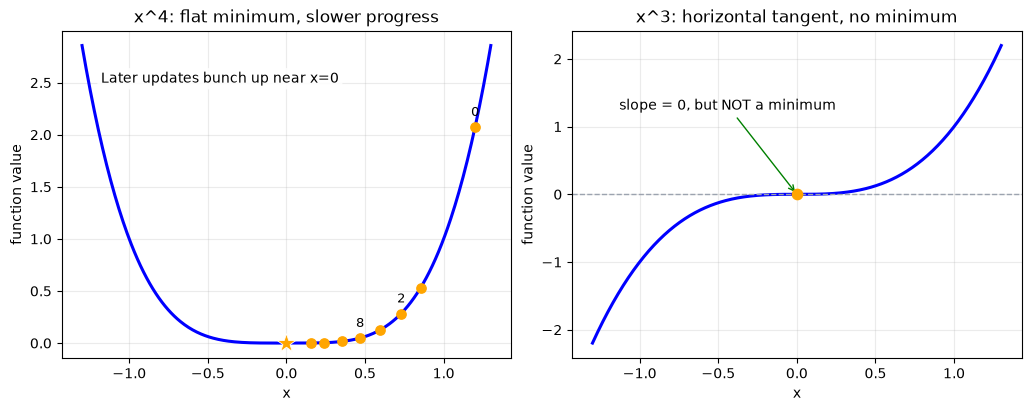

x^4: at step 0, |gradient| = 6.9120; at step 100, |gradient| = 0.0147
x^3: derivative at x=0 is 0, yet x=0 is not a minimum


In [38]:
# Tiny gradient slows descent; zero gradient does not guarantee a minimum
# change learning_rate from 0.05 to 0.1. Does a bigger step fix the slowing near zero?
learning_rate, start, steps = 0.05, 1.2, 100
path = [start]
for step in range(steps):
    x_now = path[-1]
    path.append(x_now - learning_rate * 4 * x_now**3)  # derivative of x^4 is 4x^3
path = np.array(path)

x = np.linspace(-1.3, 1.3, 400)
fig, (left, right) = plt.subplots(1, 2, figsize=(10.2, 4.0), layout="constrained")
left.plot(x, x**4, color=BLUE, lw=2.2)
points = [0, 1, 2, 4, 8, 16, 40, 100]
left.scatter(path[points], path[points]**4, color=ORANGE, s=45, zorder=4)
for n in [0, 2, 8]:
    left.annotate(str(n), (path[n], path[n]**4), xytext=(0, 8),
                  textcoords="offset points", fontsize=9, ha="center")
left.scatter([0], [0], zorder=5, **STAR)
left.text(-1.18, 2.5, "Later updates bunch up near x=0", fontsize=10,
          bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.90))
left.set_title("x^4: flat minimum, slower progress")
left.set_xlabel("x")
left.set_ylabel("function value")

right.plot(x, x**3, color=BLUE, lw=2.2)
right.axhline(0, color="#9ca3af", lw=1, ls="--")
right.scatter([0], [0], color=ORANGE, s=55, zorder=5)
right.annotate("slope = 0, but NOT a minimum", (0, 0), xytext=(-1.13, 1.25),
               arrowprops=dict(arrowstyle="->", color=INK), fontsize=10)
right.set_title("x^3: horizontal tangent, no minimum")
right.set_xlabel("x")
right.set_ylabel("function value")
for ax in (left, right):
    ax.grid(alpha=0.25)
plt.show()

print(f"x^4: at step 0, |gradient| = {abs(4*path[0]**3):.4f}; "
      f"at step {steps}, |gradient| = {abs(4*path[-1]**3):.4f}")
print("x^3: derivative at x=0 is 0, yet x=0 is not a minimum")


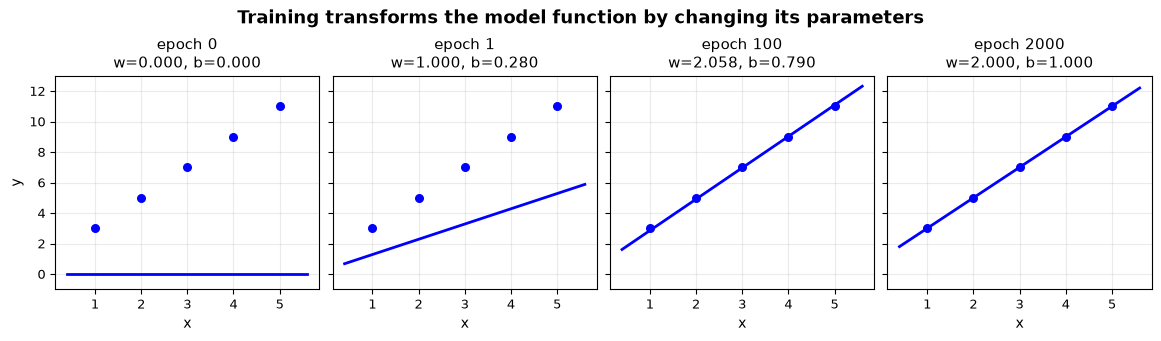

In [39]:

snapshots = [0, 1, 100, 2000]
w, b, lr = 0.0, 0.0, 0.02

history = {}
for epoch in range(max(snapshots) + 1):
    history[epoch] = (w, b)                             # the parameters after `epoch` updates
    error = y_data - (w*X_data + b)
    w -= lr * (-2*np.mean(error * X_data))
    b -= lr * (-2*np.mean(error))

line_x = np.linspace(0.4, 5.6, 50)
fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.3), sharey=True, layout="constrained")
for ax, epoch in zip(axes, snapshots):
    w, b = history[epoch]
    ax.scatter(X_data, y_data, color=BLUE, s=30, zorder=3)
    ax.plot(line_x, w*line_x + b, color=BLUE, lw=2.0)
    ax.set_title(f"epoch {epoch}\nw={w:.3f}, b={b:.3f}", fontsize=11)
    ax.set_xlabel("x", fontsize=10)
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_ylim(-1, 13)
    ax.tick_params(labelsize=9)
    ax.grid(alpha=0.25)
axes[0].set_ylabel("y", fontsize=10)
fig.suptitle("Training transforms the model function by changing its parameters",
             fontsize=13, fontweight="bold")
plt.show()


In [40]:
## Watch the line learn: fast at first, then a long crawl

lr = 0.02
shown = [0, 1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 50, 75, 100, 150, 250, 400, 700, 1200, 2000]

w, b = 0.0, 0.0
snapshot = {}
for epoch in range(max(shown) + 1):
    if epoch in shown:
        snapshot[epoch] = (w, b)                        # the parameters after `epoch` updates
    error = y_data - (w*X_data + b)
    w -= lr * (-2*np.mean(error * X_data))
    b -= lr * (-2*np.mean(error))

line_x = np.linspace(0, 6, 50)
fig, ax = plt.subplots(figsize=(8.6, 4.8), layout="constrained")
ax.scatter(X_data, y_data, color=BLUE, s=30, zorder=3)
model_line, = ax.plot([], [], color=ORANGE, lw=2.0)
ax.set_xlim(line_x.min(), line_x.max())
# INCLUDE EVERY FRAME in the same view. With lr=0.08 the first updates can overshoot
# above y=25; a fixed (-1, 14) axis silently hid them. Keep limits constant while playing.
all_lines = np.array([w_now * line_x + b_now for w_now, b_now in snapshot.values()])
visible_y = np.concatenate([all_lines.ravel(), y_data])
y_low, y_high = np.min(visible_y), np.max(visible_y)
margin = max(1.0, 0.09 * (y_high - y_low))
ax.set_ylim(y_low - margin, y_high + margin)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(alpha=0.25)

def draw(frame):
    epoch = shown[frame]
    w, b = snapshot[epoch]
    model_line.set_data(line_x, w*line_x + b)
    ax.set_title(f"epoch {epoch}:   w = {w:.3f}   b = {b:.3f}   loss = {mse(w, b):.5f}",
                 fontsize=12)

animation = FuncAnimation(fig, draw, frames=len(shown), interval=350)
plt.close(fig)
HTML(animation.to_jshtml())


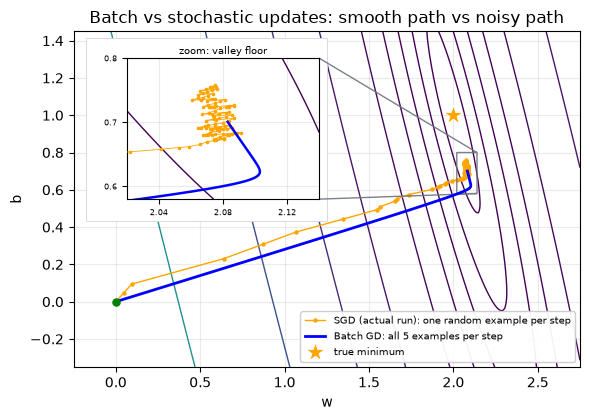

In [41]:
## Batch vs stochastic updates: smooth path vs noisy path

LR, STEPS, SEED = 0.008, 120, 11
BATCH_SIZE = 1                                          # 1 = SGD, 2 to 4 = mini-batch, 5 = all
rng = np.random.default_rng(SEED)

w, b = 0.0, 0.0
batch_path = [(w, b)]
for step in range(STEPS):                               # batch: all five examples per step
    error = y_data - (w*X_data + b)
    w, b = w - LR * (-2*np.mean(error * X_data)), b - LR * (-2*np.mean(error))
    batch_path.append((w, b))
batch_path = np.array(batch_path)

w, b = 0.0, 0.0
sgd_path = [(w, b)]
for step in range(STEPS):                               # stochastic: a random pick per step
    pick = rng.choice(len(X_data), size=BATCH_SIZE, replace=False)
    error = y_data[pick] - (w*X_data[pick] + b)
    w, b = w - LR * (-2*np.mean(error * X_data[pick])), b - LR * (-2*np.mean(error))
    sgd_path.append((w, b))
sgd_path = np.array(sgd_path)
if BATCH_SIZE == 1:
    sgd_label = "SGD (actual run): one random example per step"
elif BATCH_SIZE == len(X_data):
    sgd_label = f"All {BATCH_SIZE} examples per step: this is batch GD again"
else:
    sgd_label = f"Mini-batch (actual run): {BATCH_SIZE} random examples per step"

fig, ax = plt.subplots(figsize=(6.0, 4.3))
draw_landscape(ax, (-0.25, 2.75), (-0.35, 1.45))
ax.plot(sgd_path[:, 0], sgd_path[:, 1], color=ORANGE, lw=1.0, marker="o", ms=2.2, zorder=4,
        label=sgd_label)
ax.plot(batch_path[:, 0], batch_path[:, 1], color=BLUE, lw=2.0, zorder=5,
        label="Batch GD: all 5 examples per step")
ax.scatter([w_best], [b_best], zorder=7, label="true minimum", **STAR)
ax.scatter([0], [0], color=INK, s=26, zorder=8)
ax.legend(fontsize=7.5, loc="lower right", framealpha=0.95)
ax.set_title("Batch vs stochastic updates: smooth path vs noisy path")

# zoom on the valley floor, where the wobble is easiest to see
backing = plt.Rectangle((0.025, 0.435), 0.475, 0.545, transform=ax.transAxes,
                        fc="white", ec="#d1d5db", lw=0.6, zorder=3)
ax.add_patch(backing)
zoom = ax.inset_axes([0.105, 0.50, 0.38, 0.42], zorder=6)
draw_landscape(zoom, (2.02, 2.14), (0.58, 0.80))
zoom.plot(sgd_path[:, 0], sgd_path[:, 1], color=ORANGE, lw=0.6, marker="o", ms=1.6, zorder=4)
zoom.plot(batch_path[:, 0], batch_path[:, 1], color=BLUE, lw=1.8, zorder=5)
zoom.set_xlabel("")
zoom.set_ylabel("")
zoom.set_xticks([2.04, 2.08, 2.12])
zoom.set_yticks([0.6, 0.7, 0.8])
zoom.tick_params(labelsize=6)
zoom.set_title("zoom: valley floor", fontsize=7.5, pad=3)
ax.indicate_inset_zoom(zoom, edgecolor="#6b7280", alpha=0.9)
fig.tight_layout()
plt.show()


In [42]:

def epochs_needed(X, y, lr, good_enough=1e-6):
    w = b = 0.0
    for epoch in range(100000):
        error = y - (w*X + b)
        if np.mean(error**2) < good_enough:
            return epoch
        w, b = w - lr * (-2*np.mean(error * X)), b - lr * (-2*np.mean(error))
    return "did not finish"

X_scaled = (X_data - X_data.mean()) / X_data.std()
print("raw x,    lr=0.02 -> epochs until loss < 1e-6:", epochs_needed(X_data, y_data, 0.02))
print("scaled x, lr=0.02 -> epochs until loss < 1e-6:", epochs_needed(X_scaled, y_data, 0.02))
print("scaled x, lr=0.5  -> epochs until loss < 1e-6:", epochs_needed(X_scaled, y_data, 0.5))

raw x,    lr=0.02 -> epochs until loss < 1e-6: 763
scaled x, lr=0.02 -> epochs until loss < 1e-6: 219
scaled x, lr=0.5  -> epochs until loss < 1e-6: 1


In [48]:
## Autograd

import torch

print(torch.__version__)


2.14.1+cpu


In [49]:
w = torch.tensor(2.0, requires_grad = True)
loss = (w - 5) ** 2
loss.backward()

print(w.grad)

tensor(-6.)


In [50]:
def f(x):
    return x**2

x = 3
h = 0.0001

derivative = (f(x + h) - f(x)) / h

print(derivative)

6.000100000012054


In [51]:
f(x)

9

In [52]:
f(x + h)

9.000600010000001

In [53]:
def model(inputs):
    x, y = inputs

    output1 = x**2 + y
    output2 = x*y

    return np.array([output1, output2])

inputs = np.array([2., 3])
print(model(inputs))

[7. 6.]


In [44]:
# Jacobian vs Hessian, using only NumPy

# A Jacobian collects first derivatives of MANY outputs.
inputs = np.array([1., 2.])

def two_predictions(params):
    w, b = params
    return w * inputs + b                         # vector output: two predictions

params = np.array([2., 1.])
h = 1e-5
jacobian = np.column_stack([
    (two_predictions(params + np.eye(2)[i] * h) - two_predictions(params - np.eye(2)[i] * h)) / (2*h)
    for i in range(2)
])
print("Jacobian (outputs x parameters) =")
print(np.round(jacobian, 3))                        # [[1, 1], [2, 1]]


def toy_loss(w, b):
    return (w - 2)**2 + 3*(b - 1)**2

w, b = 0.0, 0.0
hessian = np.array([
    [(toy_loss(w+h,b)-2*toy_loss(w,b)+toy_loss(w-h,b))/h**2,
     (toy_loss(w+h,b+h)-toy_loss(w+h,b-h)-toy_loss(w-h,b+h)+toy_loss(w-h,b-h))/(4*h**2)],
    [(toy_loss(w+h,b+h)-toy_loss(w+h,b-h)-toy_loss(w-h,b+h)+toy_loss(w-h,b-h))/(4*h**2),
     (toy_loss(w,b+h)-2*toy_loss(w,b)+toy_loss(w,b-h))/h**2]
])
print("Hessian (curvature of one loss) =")
print(np.round(hessian, 3))                         # [[2, 0], [0, 6]]


Jacobian (outputs x parameters) =
[[1. 1.]
 [2. 1.]]
Hessian (curvature of one loss) =
[[2. 0.]
 [0. 6.]]


In [54]:

y_true, F_now, h = 9.0, 3.0, 1e-5

def half_squared_loss(F):
    return 0.5 * (y_true - F)**2

measured = (half_squared_loss(F_now + h) - half_squared_loss(F_now)) / h
print("measured dL/dF     :", round(measured, 3))
print("formula  F - y     :", F_now - y_true)
print("residual y - F     :", y_true - F_now, " <- the negative of the gradient")

measured dL/dF     : -6.0
formula  F - y     : -6.0
residual y - F     : 6.0  <- the negative of the gradient


In [46]:
# LAB 8 - Gradient descent on the predictions themselves
import numpy as np

rng = np.random.default_rng(0)
x = np.linspace(-3, 3, 25)
y = x**2 + rng.normal(0, 1, 25)

F = np.full(25, y.mean())        # current model: one flat prediction

for step in range(1, 11):
    residual = y - F             # negative gradient of 1/2*(y - F)^2, one per data point
    F = F + 0.3 * residual       # every prediction steps along its arrow
    print(step, round(np.mean((y - F)**2), 4))

1 5.5695
2 2.7291
3 1.3372
4 0.6552
5 0.3211
6 0.1573
7 0.0771
8 0.0378
9 0.0185
10 0.0091


In [57]:
rng = np.random.default_rng(0)
x_pts = np.linspace(-3, 3, 25)
y_pts = x_pts**2 + rng.normal(0, 1, 25)
F0 = np.full(25, y_pts.mean())
print("Flat model F0 = ", round(y_pts.mean(), 3))

Flat model F0 =  3.177


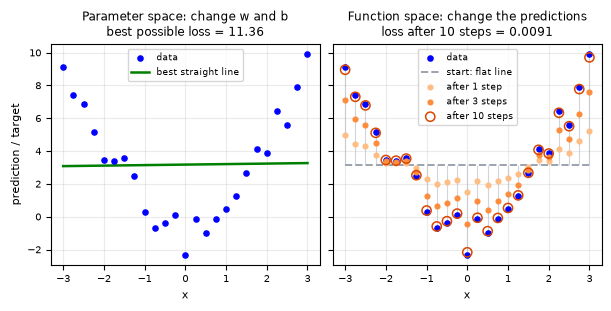

straight line:      w=0.031  b=3.177  loss=11.3633
predictions moved:  loss 11.3664 -> 0.0091 in 10 steps


In [58]:
# FIGURE 8.4 - Two ways to improve a model
# change step_size from 0.3 to 1.0. Then try 2.1.
step_size = 0.3
show_after = [1, 3, 10]

# Left: parameter space. Best straight line
w, b = 0.0, 0.0
for epoch in range(500):
    error = y_pts - (w*x_pts + b)
    w, b = w - 0.05 * (-2*np.mean(error * x_pts)), b - 0.05 * (-2*np.mean(error))
line_loss = np.mean((y_pts - (w*x_pts + b))**2)

# Right: function space. Every prediction steps along its own residual.
F = F0.copy()
snapshots, losses = {}, [np.mean((y_pts - F)**2)]
for step in range(1, max(show_after) + 1):
    F = F + step_size * (y_pts - F)
    losses.append(np.mean((y_pts - F)**2))
    snapshots[step] = F.copy()
F_moved = F

fig, (left, right) = plt.subplots(1, 2, figsize=(6.0, 3.0), sharey=True, layout="constrained")
left.scatter(x_pts, y_pts, color=BLUE, s=14, zorder=3, label="data")
left.plot(x_pts, w*x_pts + b, color=INK, lw=1.8, label="best straight line")
left.set_title(f"Parameter space: change w and b\nbest possible loss = {line_loss:.2f}",
               fontsize=8.5)
left.set_ylabel("prediction / target", fontsize=8)

right.scatter(x_pts, y_pts, color=BLUE, s=14, zorder=3, label="data")
right.plot(x_pts, F0, color="#9ca3af", lw=1.4, ls="--", label="start: flat line")
right.vlines(x_pts, F0, F_moved, color="#d1d5db", lw=0.8, zorder=1)   # one track per prediction
shades = ["#fdbe85", "#fd8d3c", "#d94701"]              # light -> dark = earlier -> later
for step, shade in zip(show_after, shades):
    last = step == max(show_after)                      # the last one is drawn as a ring
    right.scatter(x_pts, snapshots[step], s=44 if last else 11, zorder=4, linewidths=1.1,
                  facecolors="none" if last else shade, edgecolors=shade,
                  label=f"after {step} step" + ("s" if step > 1 else ""))
right.set_title("Function space: change the predictions\n"
                f"loss after {max(show_after)} steps = {losses[-1]:.4f}", fontsize=8.5)

for ax in (left, right):
    ax.set_xlabel("x", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.legend(fontsize=6.5, loc="upper center")
    ax.grid(alpha=0.25)
plt.show()

print(f"straight line:      w={w:.3f}  b={b:.3f}  loss={line_loss:.4f}")
print(f"predictions moved:  loss {losses[0]:.4f} -> {losses[-1]:.4f} in {len(losses) - 1} steps")


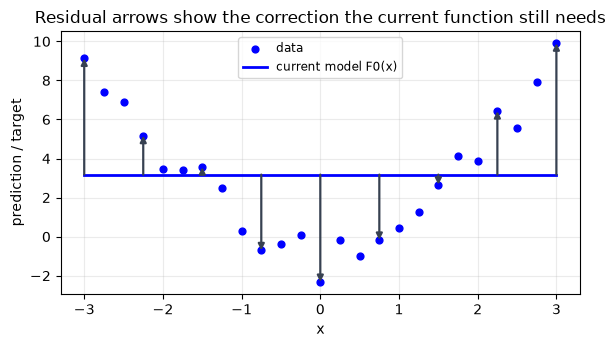

In [59]:
# FIGURE 8.5 - Residual arrows show the correction the current function still needs
# RUN FIRST: setup (cell 1) + SHARED x_pts/y_pts/F0 in Module 8.
# TRY: change every from 3 to 1 to draw all 25 arrows
every = 3

fig, ax = plt.subplots(figsize=(6.0, 3.57))
ax.scatter(x_pts, y_pts, color=BLUE, s=24, zorder=3, label="data")
ax.plot(x_pts, F0, color=BLUE, lw=2.0, label="current model F0(x)")
thin_arrow = dict(arrowstyle="-|>", color="#374151", lw=1.6, mutation_scale=9,
                  shrinkA=0, shrinkB=0)
for i in range(0, len(x_pts), every):               # from the flat model up or down to the data
    ax.annotate("", xy=(x_pts[i], y_pts[i]), xytext=(x_pts[i], F0[i]), arrowprops=thin_arrow)
ax.set_title("Residual arrows show the correction the current function still needs")
ax.set_xlabel("x")
ax.set_ylabel("prediction / target")
ax.legend(loc="upper center", fontsize=8.5)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
